# Final Project Phase 3 Summary
This Jupyter Notebook (.ipynb) will serve as the skeleton file for your submission for Phase 3 of the Final Project. Complete all sections below as specified in the instructions for the project, covering all necessary details. We will use this to grade your individual code (Do this whether you are in a group or not). Good luck! <br><br>

Note: To edit a Markdown cell, double-click on its text.

## Jupyter Notebook Quick Tips
Here are some quick formatting tips to get you started with Jupyter Notebooks. This is by no means exhaustive, and there are plenty of articles to highlight other things that can be done. We recommend using HTML syntax for Markdown but there is also Markdown syntax that is more streamlined and might be preferable. 
<a href = "https://towardsdatascience.com/markdown-cells-jupyter-notebook-d3bea8416671">Here's an article</a> that goes into more detail. (Double-click on cell to see syntax)

# Heading 1
## Heading 2
### Heading 3
#### Heading 4
<br>
<b>BoldText</b> or <i>ItalicText</i>
<br> <br>
Math Formulas: $x^2 + y^2 = 1$
<br> <br>
Line Breaks are done using br enclosed in < >.
<br><br>
Hyperlinks are done with: <a> https://www.google.com </a> or 
<a href="http://www.google.com">Google</a><br>

# Video Presentation

If you uploaded your Video Presentation to Bluejeans, YouTube, or any other streaming services, please provide the link here:


*   Video Presentation Link


Make sure the video sharing permissions are accessible for anyone with the provided link.

# Data Collection and Cleaning


Transfer/update the data collection and cleaning you created for Phase II below. You may include additional cleaning functions if you have extra datasets. If no changes are necessary, simply copy and paste your phase II parsing/cleaning functions.


In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import requests
from bs4 import BeautifulSoup

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

## Downloaded Dataset Requirement



In [65]:
def data_parser():
  # Combine separate CSV files into a single DataFrame
  dir_path = Path("../data/raw")
  file_paths = list(dir_path.glob("*.csv"))
  flight_data_separated = [pd.read_csv(file_path)[:-1] for file_path in file_paths]
  flight_data = pd.concat(flight_data_separated, ignore_index=True)

  # Convert format and datatype of date column for sorting and to use as an index with other datasets
  ## notes on format: key + examples: %Y (2026), %y (26), %m (11), %b (Nov), %B (November), %d (03)
  flight_data["Date (MM/DD/YYYY)"] = pd.to_datetime(flight_data["Date (MM/DD/YYYY)"], format="%m/%d/%Y")
  ## Rename column because format in column name no longer accurate
  flight_data.rename(columns={"Date (MM/DD/YYYY)": "Date"}, inplace=True)
  ## Create departure datetime column to compare with weather data
  ### We need to convert datetime to string for the purpose of combining the date with the time to later get the datetime object
  flight_data["Scheduled departure datetime"] = pd.to_datetime(flight_data["Date"].dt.strftime("%Y-%m-%d") + " " + flight_data["Scheduled departure time"])
  ### Round to nearest hour because dataset from API has data recorded at every hour of every day of 2025 
  flight_data["Scheduled departure hour"] = flight_data["Scheduled departure datetime"].dt.floor("h")

  # Carrier Code MQ is replaced with AA because we designate American Eagle as American Airlines
  ## This is to accurately match delays with market share since MQ == AA in terms of carriers listed in ATL market
  flight_data["Carrier Code"] = flight_data["Carrier Code"].replace("MQ", "AA")

  # Map carrier codes to airline names
  airline_codes = {"DL" : "Delta Air Lines", "F9" : "Frontier Airlines", "WN" : "Southwest Airlines", "AA" : "American Airlines", "UA" : "United Airlines", "NK" : "Spirit Airlines", "B6" : "JetBlue", "AS" : "Alaska Airlines", "AF" : "Air France", "VS" : "Virgin Atlantic"}
  flight_data["Airline"] = flight_data["Carrier Code"].map(airline_codes)

  # DataFrame to CSV
  flight_data.to_csv("../data/processed/flights.csv", index=False)

  return flight_data




############ Function Call ############
data_parser()

,Carrier Code,Date,Flight Number,Tail Number,Destination Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),Departure delay (Minutes),Wheels-off time,Taxi-Out time (Minutes),Delay Carrier (Minutes),Delay Weather (Minutes),Delay National Aviation System (Minutes),Delay Security (Minutes),Delay Late Aircraft Arrival (Minutes),Scheduled departure datetime,Scheduled departure hour,Airline
0,AS,2025-01-01,321.0,N428AS,SEA,18:39,18:36,343.0,344.0,-3.0,18:53,17.0,0.0,0.0,0.0,0.0,0.0,2025-01-01 18:39:00,2025-01-01 18:00:00,Alaska Airlines
1,AS,2025-01-01,355.0,N588AS,SAN,17:19,17:16,284.0,297.0,-3.0,17:35,19.0,0.0,0.0,0.0,0.0,0.0,2025-01-01 17:19:00,2025-01-01 17:00:00,Alaska Airlines
2,AS,2025-01-01,377.0,N278AK,SEA,07:04,06:55,343.0,336.0,-9.0,07:11,16.0,0.0,0.0,0.0,0.0,0.0,2025-01-01 07:04:00,2025-01-01 07:00:00,Alaska Airlines
3,AS,2025-01-01,497.0,N562AS,SEA,15:27,15:22,344.0,338.0,-5.0,15:34,12.0,0.0,0.0,0.0,0.0,0.0,2025-01-01 15:27:00,2025-01-01 15:00:00,Alaska Airlines
4,AS,2025-01-01,783.0,N263AK,PDX,19:59,20:07,319.0,343.0,8.0,20:23,16.0,8.0,0.0,24.0,0.0,0.0,2025-01-01 19:59:00,2025-01-01 19:00:00,Alaska Airlines
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
301124,UA,2025-12-31,632.0,N18243,IAD,09:40,09:41,110.0,107.0,1.0,09:58,17.0,0.0,0.0,0.0,0.0,0.0,2025-12-31 09:40:00,2025-12-31 09:00:00,United Airlines
301125,UA,2025-12-31,1057.0,N77598,IAH,07:10,07:09,151.0,121.0,-1.0,07:24,15.0,0.0,0.0,0.0,0.0,0.0,2025-12-31 07:10:00,2025-12-31 07:00:00,United Airlines
301126,UA,2025-12-31,1259.0,N76288,SFO,08:25,08:22,335.0,367.0,-3.0,09:31,69.0,0.0,0.0,29.0,0.0,0.0,2025-12-31 08:25:00,2025-12-31 08:00:00,United Airlines
301127,UA,2025-12-31,1831.0,N13716,IAD,14:40,14:37,110.0,105.0,-3.0,14:53,16.0,0.0,0.0,0.0,0.0,0.0,2025-12-31 14:40:00,2025-12-31 14:00:00,United Airlines


## Web Collection Requirement \#1 (JSON / API Requirement)


In [66]:
def web_parser1():
  # API Call Parameters
  ## lat and lon match with coordinates of Hartsfield-Jackson Airport
  lat = 33.6367
  lon = -84.4279
  ## we are only analyzing the departure delays frrom the year 2025
  min_date = "2025-01-01"
  max_date = "2025-12-31"
  url = "https://archive-api.open-meteo.com/v1/archive"

  params = {
    "latitude": lat,
    "longitude": lon,
    "start_date": min_date,
    "end_date": max_date,
    "temperature_unit": "fahrenheit",
    "hourly": ["temperature_2m", "relative_humidity_2m", "dew_point_2m", "apparent_temperature", "precipitation", "rain", "snowfall", "cloud_cover", "windspeed_10m", "windgusts_10m", "winddirection_10m", "weathercode"],
  }

  # API Call
  weather = requests.get(url, params=params).json()

  # JSON to DataFrame
  weather_df = pd.DataFrame(weather["hourly"])
  weather_df["time"] = pd.to_datetime(weather_df["time"])

  # DataFrame to CSV
  weather_df.to_csv("../data/processed/weather.csv", index=False)

  return weather_df





############ Function Call ############
web_parser1()

,time,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,snowfall,cloud_cover,windspeed_10m,windgusts_10m,winddirection_10m,weathercode
0,2025-01-01 00:00:00,53.1,59,39.3,45.4,0.0,0.0,0.0,0,19.5,44.6,296,0
1,2025-01-01 01:00:00,52.5,56,37.1,44.5,0.0,0.0,0.0,0,19.3,41.4,302,0
2,2025-01-01 02:00:00,50.3,60,36.8,42.1,0.0,0.0,0.0,0,19.4,41.0,303,0
3,2025-01-01 03:00:00,47.8,65,36.8,39.7,0.0,0.0,0.0,0,19.3,41.4,306,0
4,2025-01-01 04:00:00,46.1,69,36.5,38.2,0.0,0.0,0.0,1,18.6,41.0,310,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2025-12-31 19:00:00,50.0,18,8.4,40.6,0.0,0.0,0.0,18,12.6,32.4,274,0
8756,2025-12-31 20:00:00,51.0,18,9.3,41.1,0.0,0.0,0.0,1,14.2,34.9,274,0
8757,2025-12-31 21:00:00,50.9,19,10.5,40.9,0.0,0.0,0.0,27,14.6,34.9,265,1
8758,2025-12-31 22:00:00,49.4,21,11.4,39.8,0.0,0.0,0.0,5,13.4,34.2,265,0


## Web Collection Requirement #2 (HTML Requirement)

In [67]:
def web_parser2():
  url = "https://en.wikipedia.org/wiki/Federal_holidays_in_the_United_States"
  agent = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/97.0.4692.99 Safari/537.36"}
  response = requests.get(url, headers=agent)
  soup = BeautifulSoup(response.content, "html.parser")

  # Webscrape/extract holiday table
  table = soup.find("table", class_="wikitable")
  holidays = []
  for row in table.find_all("tr")[1:]:
    date = row.find("th").text.strip()
    name = row.find("td").text.strip()
    holidays.append({"Holiday": name, "Date": date})

  # List to DataFrame
  holidays_df = pd.DataFrame(holidays)

  # Convert Date in words to Date Range
  ## We only analyze 2025 dates. We assume that that the accetable range is a maximum of 6 days before and after big holidays
  ## date for the departure to be reasonably associated with the holiday.
  year = 2025
  hdRange = 6
  bigHolidays = ["New Year's Day", "Independence Day", "Thanksgiving Day","Christmas Day"]
  ## Split strings like "January 15–21(Third Monday)" into month, start day, and end day 
  ### where the end day is NaN for single dates
  #### hyphen not required because of single dates, so we need a noncapturing group
  ##### wikipedia uses en dash, so create character class of hypens to ensure range is captured  
  dateParts = holidays_df["Date"].str.extract(r"([A-Za-z]+)\s+(\d+)(?:[–-](\d+))?")
  dateParts.columns = ["Month", "Start Day", "End Day"]
  ## format %B because month given in full proper noun i.e. January vs Jan
  month = pd.to_datetime(dateParts["Month"], format="%B").dt.month
  ### If the holiday was provided as a single date, then the start day is the end day
  dateParts["End Day"] = dateParts["End Day"].fillna(dateParts["Start Day"])
  ## create start and end days as series of datetime objects
  start = pd.to_datetime(pd.DataFrame({"year": year, "month": month, "day": dateParts["Start Day"].astype(int)}))
  end = pd.to_datetime(pd.DataFrame({"year": year, "month": month, "day": dateParts["End Day"].astype(int)}))
  ## find the dates that start and end the range of each "holiday season"
  ### we need to make sure we filter big holidays which have larger seasons than smaller holidays
  isBH = holidays_df["Holiday"].isin(bigHolidays)
  #### .where(cond, input if cond is false)
  ### TimeDelta basically lets me add or subtract x amount of time from a datetime object
  holidays_df["Start"] = start.where(~isBH, start - pd.Timedelta(days=hdRange))
  holidays_df["End"] = end.where(~isBH, end + pd.Timedelta(days=hdRange))
 #holidays_df = holidays_df.drop(columns="Date")
  ## Date column has been reformatted and renamed 
  holidays_df["Date"] = holidays_df["Start"].astype(str)+ " - " + holidays_df["End"].astype(str)
  holidays_df.rename(columns={"Date" : "Date Range"}, inplace = True)

  # DataFrame to CSV
  holidays_df.to_csv("../data/processed/holidays.csv", index=False)

  return holidays_df





############ Function Call ############
web_parser2()

,Holiday,Date Range,Start,End
0,New Year's Day,2024-12-26 - 2025-01-07,2024-12-26,2025-01-07
1,"Birthday of Martin Luther King, Jr.",2025-01-15 - 2025-01-21,2025-01-15,2025-01-21
2,Washington's Birthday,2025-02-15 - 2025-02-21,2025-02-15,2025-02-21
3,Memorial Day,2025-05-25 - 2025-05-31,2025-05-25,2025-05-31
4,Juneteenth National Independence Day,2025-06-19 - 2025-06-19,2025-06-19,2025-06-19
5,Independence Day,2025-06-28 - 2025-07-10,2025-06-28,2025-07-10
6,Labor Day,2025-09-01 - 2025-09-07,2025-09-01,2025-09-07
7,Columbus Day,2025-10-08 - 2025-10-14,2025-10-08,2025-10-14
8,Veterans Day,2025-11-11 - 2025-11-11,2025-11-11,2025-11-11
9,Thanksgiving Day,2025-11-16 - 2025-12-04,2025-11-16,2025-12-04


In [68]:
### Function to add boolean column/series into flight_data so we can easily analyze and compare dates which are now
### assigned True for being within any holiday season
def isHoliday():
  flight_data = pd.read_csv("../data/processed/flights.csv")
  holidays_df = pd.read_csv("../data/processed/holidays.csv")
  flight_data["Date"] = pd.to_datetime(flight_data["Date"])
  holidays_df["Start"] = pd.to_datetime(holidays_df["Start"])
  holidays_df["End"] = pd.to_datetime(holidays_df["End"])
  #### if the Date in flight data is between any holiday season range across all the seasons in holidays, then we can say True
  #### for the Date being within a holiday season
  flight_data["Is Holiday Season"] = holidays_df.apply(lambda row: flight_data["Date"].between(row["Start"], row["End"]), axis=1).any(axis=0)
  flight_data.to_csv("../data/processed/flights.csv", index=False)
  return flight_data

isHoliday()

,Carrier Code,Date,Flight Number,Tail Number,Destination Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),Departure delay (Minutes),...,Taxi-Out time (Minutes),Delay Carrier (Minutes),Delay Weather (Minutes),Delay National Aviation System (Minutes),Delay Security (Minutes),Delay Late Aircraft Arrival (Minutes),Scheduled departure datetime,Scheduled departure hour,Airline,Is Holiday Season
0,AS,2025-01-01,321.0,N428AS,SEA,18:39,18:36,343.0,344.0,-3.0,...,17.0,0.0,0.0,0.0,0.0,0.0,2025-01-01 18:39:00,2025-01-01 18:00:00,Alaska Airlines,True
1,AS,2025-01-01,355.0,N588AS,SAN,17:19,17:16,284.0,297.0,-3.0,...,19.0,0.0,0.0,0.0,0.0,0.0,2025-01-01 17:19:00,2025-01-01 17:00:00,Alaska Airlines,True
2,AS,2025-01-01,377.0,N278AK,SEA,07:04,06:55,343.0,336.0,-9.0,...,16.0,0.0,0.0,0.0,0.0,0.0,2025-01-01 07:04:00,2025-01-01 07:00:00,Alaska Airlines,True
3,AS,2025-01-01,497.0,N562AS,SEA,15:27,15:22,344.0,338.0,-5.0,...,12.0,0.0,0.0,0.0,0.0,0.0,2025-01-01 15:27:00,2025-01-01 15:00:00,Alaska Airlines,True
4,AS,2025-01-01,783.0,N263AK,PDX,19:59,20:07,319.0,343.0,8.0,...,16.0,8.0,0.0,24.0,0.0,0.0,2025-01-01 19:59:00,2025-01-01 19:00:00,Alaska Airlines,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
301124,UA,2025-12-31,632.0,N18243,IAD,09:40,09:41,110.0,107.0,1.0,...,17.0,0.0,0.0,0.0,0.0,0.0,2025-12-31 09:40:00,2025-12-31 09:00:00,United Airlines,True
301125,UA,2025-12-31,1057.0,N77598,IAH,07:10,07:09,151.0,121.0,-1.0,...,15.0,0.0,0.0,0.0,0.0,0.0,2025-12-31 07:10:00,2025-12-31 07:00:00,United Airlines,True
301126,UA,2025-12-31,1259.0,N76288,SFO,08:25,08:22,335.0,367.0,-3.0,...,69.0,0.0,0.0,29.0,0.0,0.0,2025-12-31 08:25:00,2025-12-31 08:00:00,United Airlines,True
301127,UA,2025-12-31,1831.0,N13716,IAD,14:40,14:37,110.0,105.0,-3.0,...,16.0,0.0,0.0,0.0,0.0,0.0,2025-12-31 14:40:00,2025-12-31 14:00:00,United Airlines,True


## Additional Dataset Parsing/Cleaning Functions

In [69]:
airline_codes = {"Delta Air Lines" : "DL", "Frontier Airlines" : "F9", "Southwest Airlines" : "WN", "American Airlines" : "AA", "United Airlines" : "UA", "Spirit Airlines" : "NK", "JetBlue" : "B6", "Alaska Airlines" : "AS", "Air France" : "AF", "Virgin Atlantic" : "VS"}
def extra_source1():
    url = "https://en.wikipedia.org/wiki/Hartsfield-Jackson_Atlanta_International_Airport"
    agent = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/97.0.4692.99 Safari/537.36"}
    response = requests.get(url, headers=agent)
    soup = BeautifulSoup(response.content, "html.parser")

    market_shares = []
    #section = soup.find("section", aria_labelledby="Airline_market_share")
    #section = soup.find(id="Airline_market_share")
    section = soup.select_one('section[aria-labelledby="Airline_market_share"]')
    ## .select_one finds first HTML element that matches a CSS selector
    table = section.find("table")
    for row in table.find_all("tr")[1:]:
        entries = [cell.text.strip() for cell in row.find_all("td")]
        market_shares.append(entries)

    # List to DataFrame
    market_shares_df = pd.DataFrame(market_shares, columns=["Rank", "Airline", "Passengers", "Share"])
    
    # Working with dataframe
    ## Remove info kept in () in name of the airline * only applies to Delta and American
    market_shares_df["Airline"] = market_shares_df["Airline"].str.replace(r"\s*\(.*?\)", "", regex=True).str.strip()
    ## Add columnn matching airline to its corresponding airline code.
    market_shares_df["Carrier Code"] = market_shares_df["Airline"].map(airline_codes)
    ## Re-order the columns so that carrier code is right after Airline
    market_shares_df = market_shares_df[["Rank", "Airline", "Carrier Code", "Passengers", "Share"]]
    ## Drop Other airlines because we do not have any other carriers in the csv file of departure delays.
    ### Value of Other's Carrier Code is NaN.
    market_shares_df = market_shares_df.dropna(subset = ["Carrier Code"])
    ## Convert string of market share percentage into float value for analysis. 
    market_shares_df["Share"] = np.round(market_shares_df["Share"].str.rstrip("%").astype(float) / 100, 4)
    ## We set the Rank column as the index because the rank already orders the airlines by the share.
    market_shares_df = market_shares_df.set_index("Rank")

    # DataFrame to CSV
    market_shares_df.to_csv("../data/processed/market_shares.csv", index=False)

    return market_shares_df

    
############ Function Call ############
extra_source1()

,Airline,Carrier Code,Passengers,Share
Rank,,,,
1,Delta Air Lines,DL,"85,009,687",0.8029
2,Frontier Airlines,F9,"7,135,330",0.0674
3,Southwest Airlines,WN,"3,871,271",0.0366
4,American Airlines,AA,"2,658,779",0.0251
5,United Airlines,UA,"1,936,211",0.0183
6,Spirit Airlines,NK,"970,799",0.0092
7,JetBlue,B6,"681,524",0.0064
8,Alaska Airlines,AS,"401,372",0.0038
9,Air France,AF,"367,115",0.0035


# Inconsistency Revisions (IGNORED)

 **If you were requested to revise your inconsistency section from Phase II, enter your responses here. Otherwise, ignore this section.**

For each inconsistency (NaN, null, duplicate values, empty strings, etc.) you discover in your datasets, write at least 2 sentences stating the significance, how you identified it, and how you handled it.

1. 

2. 

3. 

4. (if applicable)

5. (if applicable)


## Data Sources

Include sources (as links) to your datasets. If any of these are different from your sources used in Phase II, please <b>clearly</b> specify.

*   Downloaded Dataset Source: https://github.com/stabweee/FlightDelay/blob/main/data/interim/ATL_combined.csv
*   ^ Downloaded From: https://www.transtats.bts.gov/ONTIME/Departures.aspx
*   Web Collection #1 (JSON/API) Source: https://open-meteo.com/en/docs/historical-weather-api
*   Web Collection #2 (HTML/Webscrape) Source: https://en.wikipedia.org/wiki/Federal_holidays_in_the_United_States
*   Additional Dataset: https://en.wikipedia.org/wiki/Hartsfield%E2%80%93Jackson_Atlanta_International_Airport#Airline_market_share



# Data Analysis
For the Data Analysis section, you are required to utilize your data to complete the following:

*   Create at least 5 insights
*   Generate at least 3 data visualizations

Create a function for each of the following sections mentioned above. Do not forget to fill out the explanation section for each function. 

Make sure your data analysis is not too simple. Performing complex aggregation and using modules not taught in class shows effort, which will increase the chance of receiving full credit. 

# Topic Summary

Please provide a brief executive summary (5 sentences or less) discussing your topic:

Our topic is an analysis of departure delays from ATL (KATL) because we both had delayed flights when traveling to and from Atlanta, so we wanted to understand the reasons why flights could be delayed. We are looking to learn about the degree to which weather, holiday seasons, and airline market share at ATL affect flight delays.
As a result, this is an analysis of departure delays from Hartsfield-Jackson Airport in Atlanta, Georgia, during 2025 and the relation of the delays with weather conditions, holiday timelines, and airline market share.


## Insights

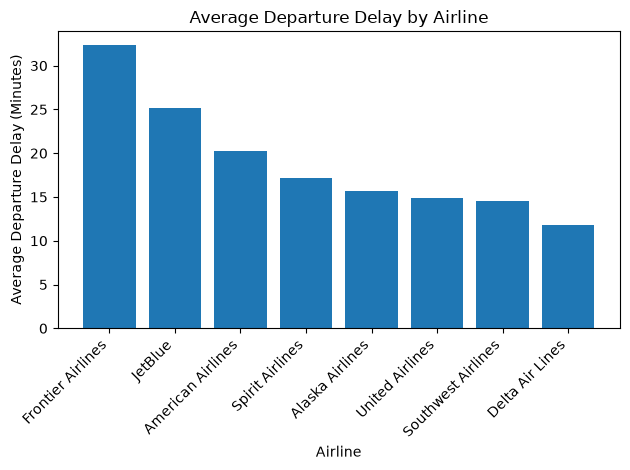

Average Departure Delay by Airline:
              Airline  Departure delay (Minutes)
3   Frontier Airlines                  32.302739
4             JetBlue                  25.200265
1   American Airlines                  20.259018
6     Spirit Airlines                  17.156775
0     Alaska Airlines                  15.689948
7     United Airlines                  14.904050
5  Southwest Airlines                  14.562174
2     Delta Air Lines                  11.795572


In [70]:
def insight1():
    # Load the processed flight data
    flight_data = pd.read_csv("../data/processed/flights.csv")
    
    # Calculate the average departure delay for each airline
    avg_delay_by_airline = flight_data.groupby("Airline")["Departure delay (Minutes)"].mean().reset_index()
    
    # Sort the airlines by average delay in descending order
    avg_delay_by_airline = avg_delay_by_airline.sort_values(by="Departure delay (Minutes)", ascending=False)
    
    # Display the results
    plt.bar(avg_delay_by_airline["Airline"], avg_delay_by_airline["Departure delay (Minutes)"])
    plt.xticks(rotation=45, ha="right")
    plt.xlabel("Airline")
    plt.ylabel("Average Departure Delay (Minutes)")
    plt.title("Average Departure Delay by Airline")
    plt.tight_layout()
    plt.show()
    
    print("Average Departure Delay by Airline:")
    print(avg_delay_by_airline)





############ Function Call ############
insight1()

### Insight 1 Explanation

Insight 1 shows the average departure delay by airline. We read from flights.csv for flight delay data. We group the DataFrame by airline and aggregate using the mean of departure delay in minutes to find the mean departure delay of each airline. We sort these means in descending order and use matplotlib to visualize it in a bar plot, allowing us to see which airlines have the longest average departure delay time.

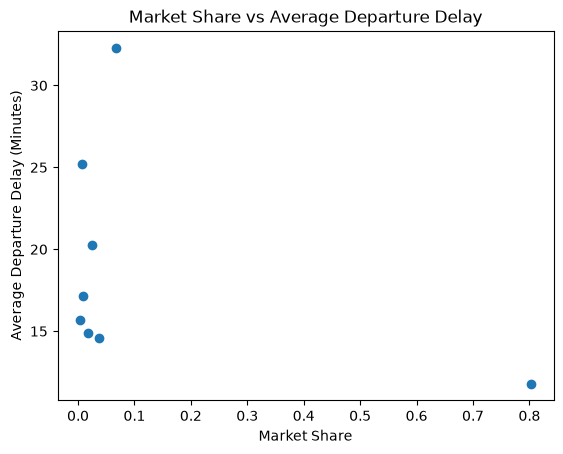

Correlation between Market Share and Average Departure Delay:
-0.3878143397860107


In [71]:
def insight2():
  # Load the processed flight and market share data
  flight_data = pd.read_csv("../data/processed/flights.csv")
  market_shares_df = pd.read_csv("../data/processed/market_shares.csv")

  # Calculate the average departure delay for each airline
  avg_delay_by_airline = flight_data.groupby("Airline")["Departure delay (Minutes)"].mean().reset_index()

  # Merge the average delay data with market share data
  merged_data = pd.merge(avg_delay_by_airline, market_shares_df, on="Airline")

  plt.scatter(merged_data["Share"], merged_data["Departure delay (Minutes)"])
  plt.xlabel("Market Share")
  plt.ylabel("Average Departure Delay (Minutes)")
  plt.title("Market Share vs Average Departure Delay")
  plt.show()

  print("Correlation between Market Share and Average Departure Delay:")
  print(merged_data["Share"].corr(merged_data["Departure delay (Minutes)"]))


############ Function Call ############
insight2()

### Insight 2 Explanation

We compare the average departure delay with market share by airline. There is not much of a linear correlation between these two variables. The correlation coefficient is -0.3878 and the graph does not show any linear relationship. However, it is interesting that the airline that dominates the ATL market (Delta) has the lowest average departure delay by quite a large margin, as one would expect a larger quantity of flights to mean a larger average departure delay due to logistic conflicts, etc. This could suggest that a key indicator or requirement of airline success is operational efficiency.

In [72]:
def insight3():
  flights = pd.read_csv("../data/processed/flights.csv")
  # i want to know the total number of flights (i.e. departures) and how many of them fall in / outside of a holiday season 
  totalFlights = len(flights)
  holidayFlights = flights["Is Holiday Season"].sum()
  nonHolidayFlights = totalFlights - holidayFlights
  ## we want to find all the delays, since we're only analyzing delays in departures. we're not analyzing all departures.
  delays = flights[flights["Departure delay (Minutes)"] > 15]
  totalDelays = len(delays)
  holidayDelays = delays["Is Holiday Season"].sum()
  nonHolidayDelays = totalDelays - holidayDelays
  ### i want to find the ratio of holiday stuff to total stuff
  flightRatio = holidayFlights / totalFlights
  delayRatio = holidayDelays / totalDelays
  ### next, i want to find the ratios of delays to departures to compare
  overallRatio = totalDelays / totalFlights
  holidayRatio = holidayDelays / holidayFlights
  nonHolidayRatio = nonHolidayDelays / nonHolidayFlights
  #### print these findings first. also i want to turn the ratios into percentages
  print("Departure Statistics in Relation to Holiday Seasons")
  print(f"Total flights: {totalFlights}")
  print(f"Flights in holiday season: {holidayFlights}")
  print(f"Flights not in holiday season: {nonHolidayFlights}")
  print(f"Percent of total flights in holiday season: {round(flightRatio * 100, 2)}%")
  print("\n")
  print("Delay Statistics in Relation to Holiday Seasons")
  print(f"Total delays: {totalDelays}")
  print(f"Delays in holiday season: {holidayDelays}")
  print(f"Delays not in holiday season: {nonHolidayDelays}")
  print(f"Percent of total delays in holiday season: {round(delayRatio * 100, 2)}%")
  print("\n")
  print("Delay-to-Departure Ratios in Relation to Holiday Seasons")
  print(f"Percent of total flights delayed: {round(overallRatio * 100, 2)}%")
  print(f"Percent of holiday flights delayed: {round(holidayRatio * 100, 2)}%")
  print(f"Percent of non-holiday flights delayed: {round(nonHolidayRatio * 100, 2)}%")
  print("\n")

  # This next aspect of the insight finds compares ATL by whether or not it's a holiday season by analyzing the number of delays and average delay length
  analysis = delays.groupby("Is Holiday Season")["Departure delay (Minutes)"].aggregate(NumberOfDelays = "count", AverageDelayMinutes = "mean")
  print(analysis)

############ Function Call ############
insight3()

Departure Statistics in Relation to Holiday Seasons
Total flights: 301129
Flights in holiday season: 71403
Flights not in holiday season: 229726
Percent of total flights in holiday season: 23.71%


Delay Statistics in Relation to Holiday Seasons
Total delays: 67873
Delays in holiday season: 16970
Delays not in holiday season: 50903
Percent of total delays in holiday season: 25.0%


Delay-to-Departure Ratios in Relation to Holiday Seasons
Percent of total flights delayed: 22.54%
Percent of holiday flights delayed: 23.77%
Percent of non-holiday flights delayed: 22.16%


                   NumberOfDelays  AverageDelayMinutes
Is Holiday Season                                     
False                       50903            67.936723
True                        16970            67.135415


### Insight 3 Explanation

Insert explanation here

In [73]:
def insight4():
  pass





############ Function Call ############
insight4()

### Insight 4 Explanation

Insert explanation here

In [74]:
def insight5():
  pass





############ Function Call ############
insight5()

### Insight 5 Explanation

Insert explanation here

## Data Visualizations

In [75]:
def visual1():
  pass





############ Function Call ############
visual1()

### Visualization 1 Explanation

Insert explanation here

In [76]:
def visual2():
  pass





############ Function Call ############
visual2()

### Visualization 2 Explanation

Insert explanation here

In [77]:
def visual3():
  pass





############ Function Call ############
visual3()

### Visualization 3 Explanation

Insert explanation here

# Cited Sources

If you used any additional sources to complete your Data Analysis section, list them here:


*   Example Module Documentation
*   Example Stack Overflow Assistance



# Graphical User Interface (GUI) Implementation
If you decide to create a GUI for Phase II, please create a separate Python file (.py) to build your GUI. You must submit both the completed PhaseII.ipynb and your Python GUI file.

# Submission

Prior to submitting your notebook to Gradescope, be sure to <b>run all functions within this file</b>. We will not run your functions ourselves, so we must see your outputs within this file in order to receive full credit.
